we are going to build a parameterized variational quantum circuit using Qiskit. The goal is to understand how tunable parameters can control quantum gates, how changing those values changes the quantum state, and why this idea is important for algorithms such as VQE (Variational Quantum Eigensolver) and QAOA (Quantum Approximate Optimization Algorithm).

In [2]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import numpy as np

In [3]:
theta = Parameter("θ")

print(theta)

θ


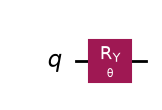

In [4]:
variational_circuit = QuantumCircuit(1)

variational_circuit.ry(theta, 0)

variational_circuit.draw("mpl")

In [5]:
print("Circuit parameters:")
print(variational_circuit.parameters)

Circuit parameters:
ParameterView([Parameter(θ)])


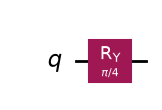

In [6]:
theta_value = np.pi / 4

bound_circuit = variational_circuit.assign_parameters(
    {theta: theta_value}
)

bound_circuit.draw("mpl")

In [7]:
state = Statevector.from_instruction(bound_circuit)

print(state)

Statevector([0.92387953+0.j, 0.38268343+0.j],
            dims=(2,))


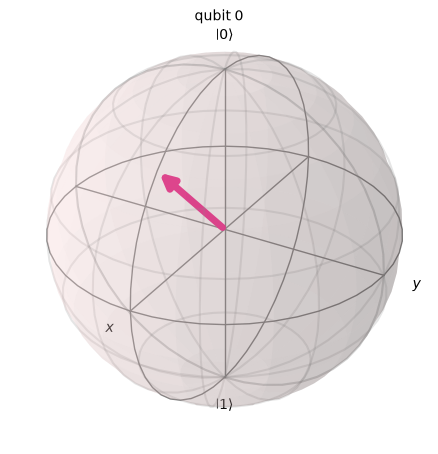

In [8]:
plot_bloch_multivector(state)

In [9]:
parameter_values = [
    0,
    np.pi / 4,
    np.pi / 2,
    np.pi
]

print(parameter_values)

[0, 0.7853981633974483, 1.5707963267948966, 3.141592653589793]


In [10]:
states = {}

for value in parameter_values:
    circuit = variational_circuit.assign_parameters(
        {theta: value}
    )

    states[value] = Statevector.from_instruction(circuit)

    print(f"Theta = {value:.3f}")
    print(states[value].data)
    print()

Theta = 0.000
[1.+0.j 0.+0.j]

Theta = 0.785
[0.92387953+0.j 0.38268343+0.j]

Theta = 1.571
[0.70710678+0.j 0.70710678+0.j]

Theta = 3.142
[6.123234e-17+0.j 1.000000e+00+0.j]



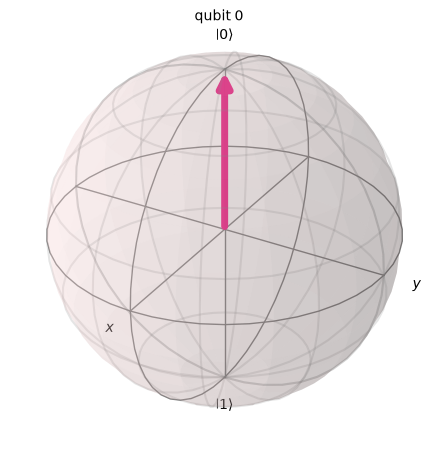

In [11]:
plot_bloch_multivector(states[0])

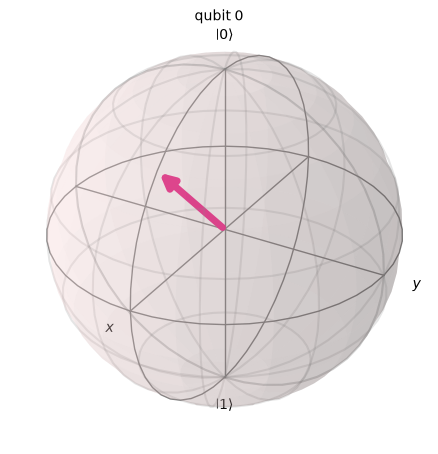

In [12]:
plot_bloch_multivector(states[np.pi / 4])

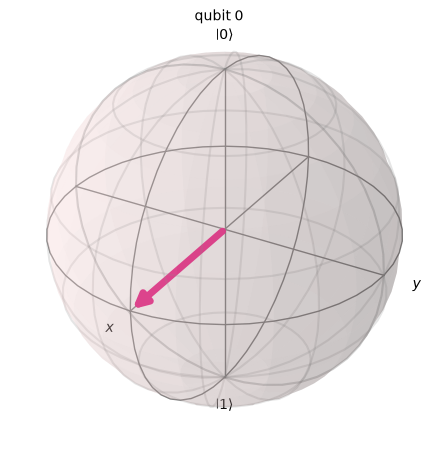

In [13]:
plot_bloch_multivector(states[np.pi / 2])

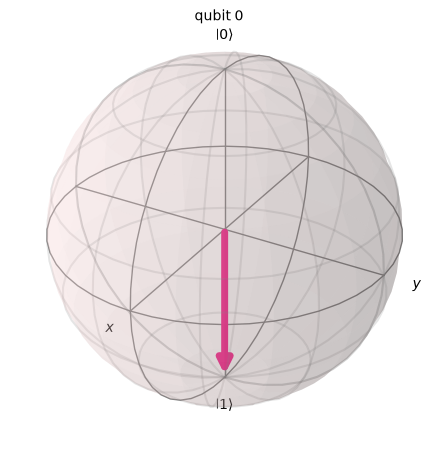

In [14]:
plot_bloch_multivector(states[np.pi])

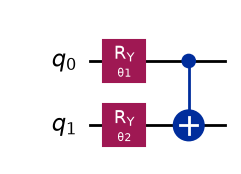

In [15]:
theta_1 = Parameter("θ1")
theta_2 = Parameter("θ2")

two_qubit_circuit = QuantumCircuit(2)

two_qubit_circuit.ry(theta_1, 0)
two_qubit_circuit.ry(theta_2, 1)

two_qubit_circuit.cx(0, 1)

two_qubit_circuit.draw("mpl")

In [16]:
print(two_qubit_circuit.parameters)

ParameterView([Parameter(θ1), Parameter(θ2)])


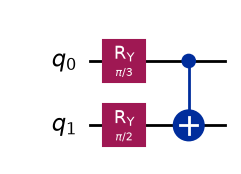

In [17]:
parameterized_instance = two_qubit_circuit.assign_parameters(
    {
        theta_1: np.pi / 3,
        theta_2: np.pi / 2
    }
)

parameterized_instance.draw("mpl")

In [18]:
two_qubit_state = Statevector.from_instruction(
    parameterized_instance
)

print(two_qubit_state)

Statevector([0.61237244+0.j, 0.35355339+0.j, 0.61237244+0.j,
             0.35355339+0.j],
            dims=(2, 2))


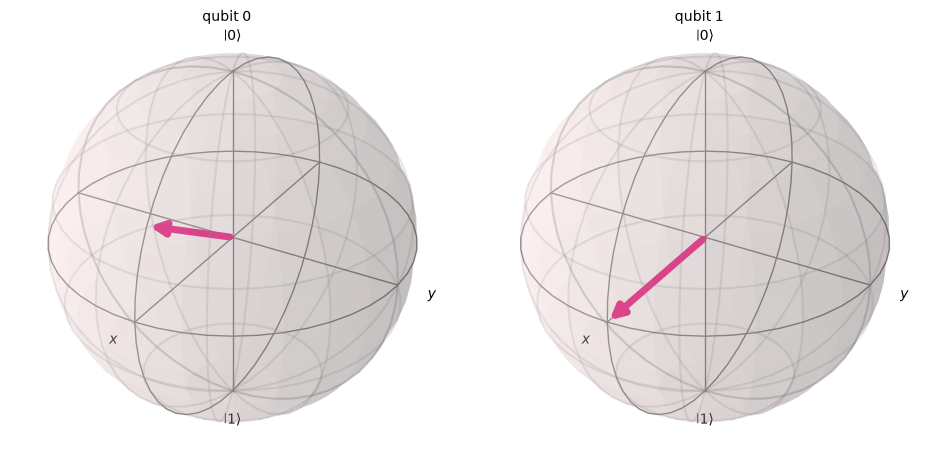

In [19]:
plot_bloch_multivector(two_qubit_state)

In [20]:
parameter_sets = [
    (0, 0),
    (np.pi / 4, np.pi / 4),
    (np.pi / 2, np.pi / 2),
    (np.pi, np.pi / 2)
]

for value_1, value_2 in parameter_sets:

    test_circuit = two_qubit_circuit.assign_parameters(
        {
            theta_1: value_1,
            theta_2: value_2
        }
    )

    test_state = Statevector.from_instruction(
        test_circuit
    )

    probabilities = test_state.probabilities_dict()

    print(
        f"θ1 = {value_1:.3f}, "
        f"θ2 = {value_2:.3f}"
    )

    print(probabilities)
    print()

θ1 = 0.000, θ2 = 0.000
{np.str_('00'): np.float64(1.0)}

θ1 = 0.785, θ2 = 0.785
{np.str_('00'): np.float64(0.7285533905932737), np.str_('01'): np.float64(0.021446609406726238), np.str_('10'): np.float64(0.12500000000000003), np.str_('11'): np.float64(0.12500000000000003)}

θ1 = 1.571, θ2 = 1.571
{np.str_('00'): np.float64(0.2500000000000001), np.str_('01'): np.float64(0.2500000000000001), np.str_('10'): np.float64(0.2500000000000001), np.str_('11'): np.float64(0.2500000000000001)}

θ1 = 3.142, θ2 = 1.571
{np.str_('00'): np.float64(1.8746997283273227e-33), np.str_('01'): np.float64(0.5000000000000001), np.str_('10'): np.float64(1.8746997283273227e-33), np.str_('11'): np.float64(0.5000000000000001)}

